<a href="https://colab.research.google.com/github/Awimya-Rn/PCVK26_13_Ilham/blob/main/week7_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum
### Global Threshold

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


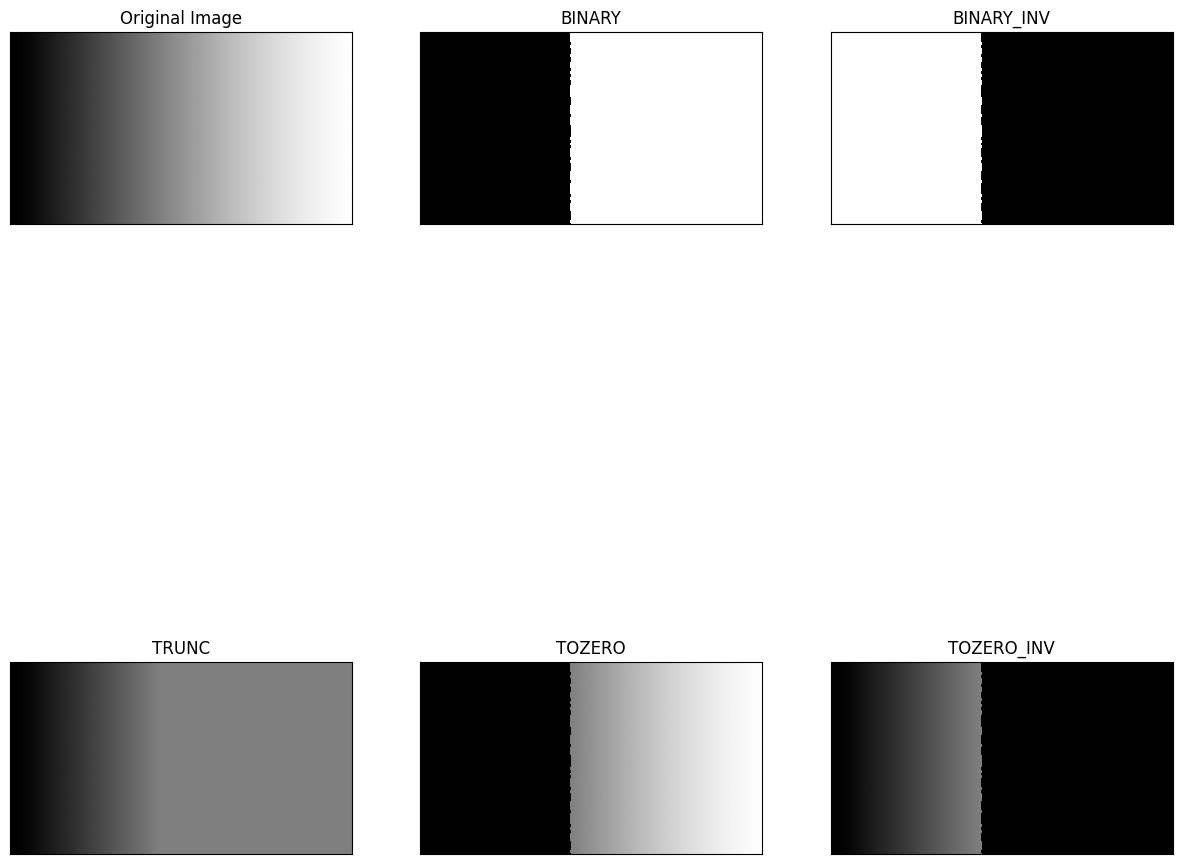

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/gradient.jpg')
img = cv.imread(filename)
thresh = 127
maxValue = 255

ret,thresh1 = cv.threshold(img,thresh,maxValue,cv.THRESH_BINARY)
ret,thresh2 = cv.threshold(img,thresh,maxValue,cv.THRESH_BINARY_INV)
ret,thresh3 = cv.threshold(img,thresh,maxValue,cv.THRESH_TRUNC)
ret,thresh4 = cv.threshold(img,thresh,maxValue,cv.THRESH_TOZERO)
ret,thresh5 = cv.threshold(img,thresh,maxValue,cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img,thresh1,thresh2,thresh3,thresh4,thresh5]

plt.figure(figsize=(15,15))
for i in range(len(images)):
  plt.subplot(2,3,i+1), plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

###  Adaptive Threshold

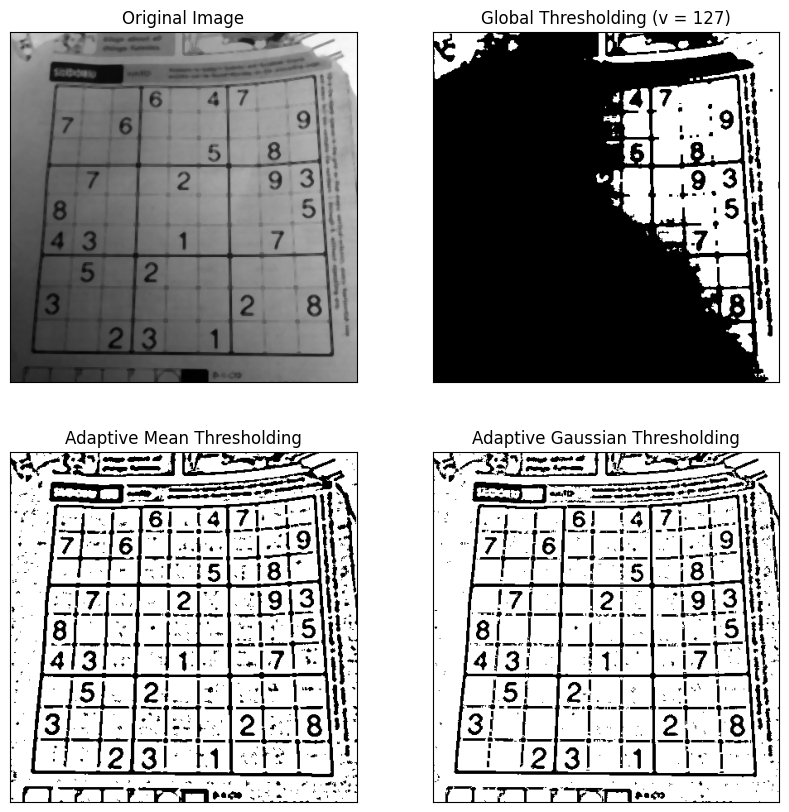

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename),5)
gray = cv.cvtColor(citra,cv.COLOR_BGR2GRAY)

ret,th1 = cv.threshold(gray,thresh,maxValue,cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray,maxValue,cv.ADAPTIVE_THRESH_MEAN_C,cv.THRESH_BINARY,11,2)
th3 = cv.adaptiveThreshold(gray,maxValue,cv.ADAPTIVE_THRESH_GAUSSIAN_C,cv.THRESH_BINARY,11,2)

titles = ['Original Image', 'Global Thresholding (v = 127)', 'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
citra2 = [gray,th1,th2,th3]

plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

### Otsu’s Threshold

/tmp/ipykernel_801/3987085914.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(2,2,1), plt.hist(blur.ravel(),256,[50,200])


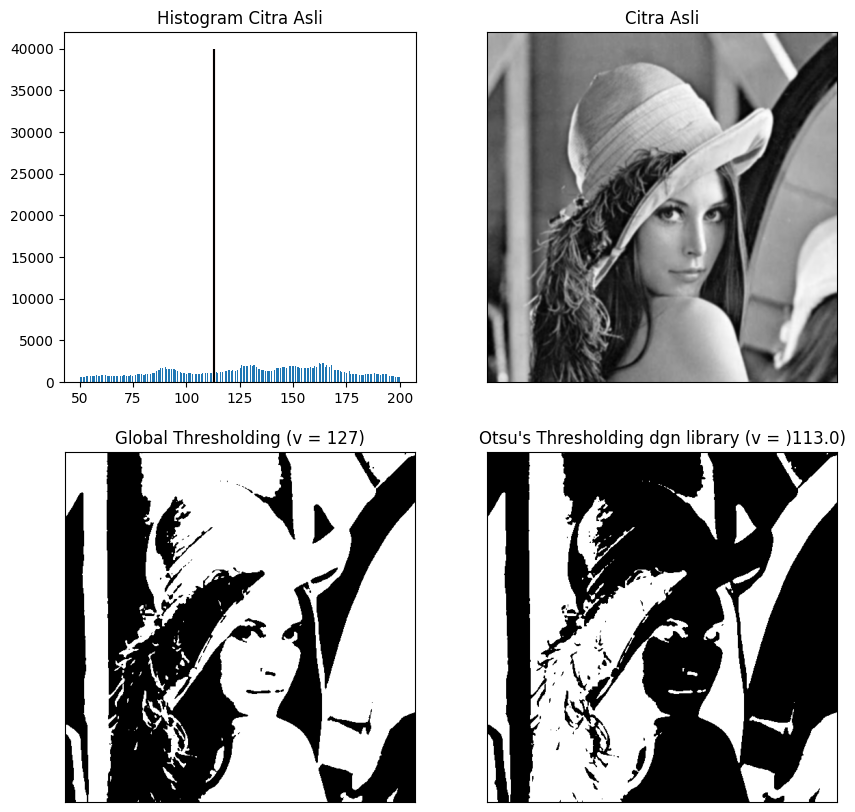

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/lena.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)

ret,th1 = cv.threshold(blur,thresh,maxValue,cv.THRESH_BINARY+cv.THRESH_OTSU)
ret2,th2 = cv.threshold(blur,0,maxValue,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)

x = ("Otsu's Thresholding dgn library (v = )"+str(ret2)+")")
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize=(10,10))
plt.subplot(2,2,1), plt.hist(blur.ravel(),256,[50,200])
plt.vlines(ret,0,40000,colors='red')
plt.vlines(ret2,0,40000,colors='black')
plt.title('Histogram Citra Asli')
for i in range(len(citra3)):
  plt.subplot(2,2,i+2),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

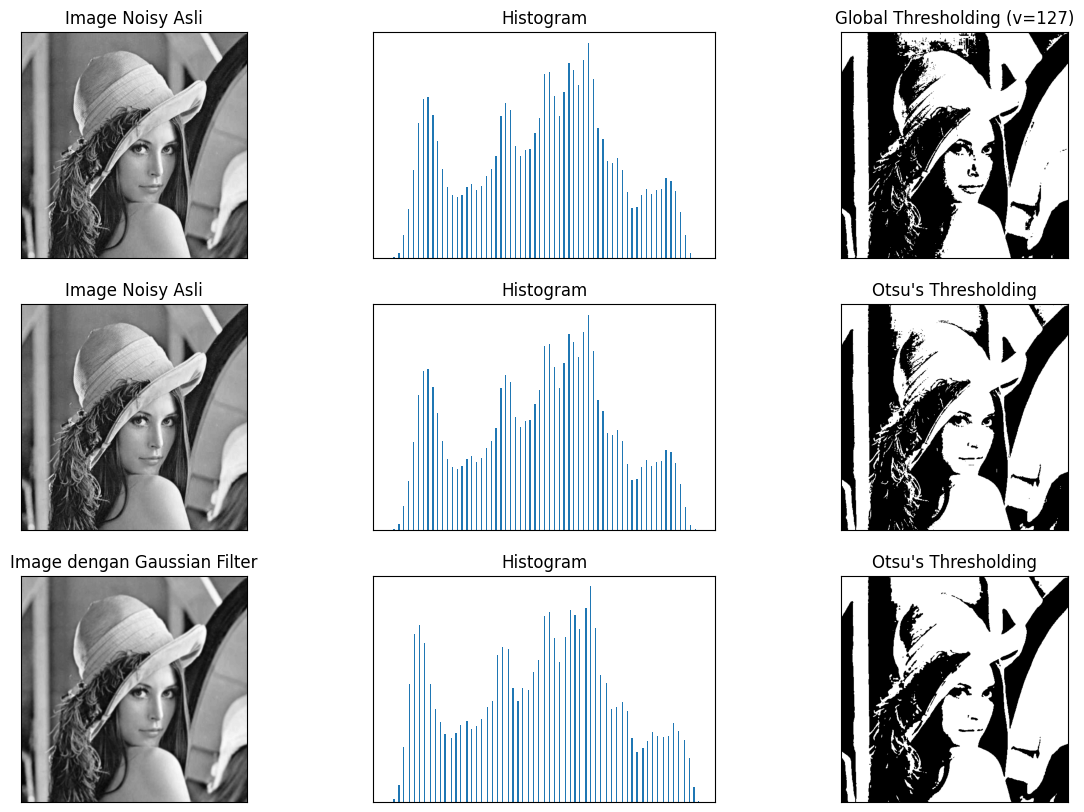

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/lena_lc.jpg')
img = cv.imread(filename,0)

ret1,th1 = cv.threshold(img,127,255,cv.THRESH_BINARY)
ret2,th2 = cv.threshold(img,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
blur = cv.GaussianBlur(img,(5,5),0)
ret3,th3 = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
images = [img, 0, th1, img, 0, th2, blur, 0, th3]
titles = ['Image Noisy Asli','Histogram','Global Thresholding (v=127)', 'Image Noisy Asli','Histogram',"Otsu's Thresholding", 'Image dengan Gaussian Filter','Histogram',"Otsu's Thresholding"]

plt.figure(figsize = (15,10))
for i in range(3):
  plt.subplot(3,3,i*3+1),plt.imshow(images[i*3],'gray')
  plt.title(titles[i*3]), plt.xticks([]), plt.yticks([])
  plt.subplot(3,3,i*3+2),plt.hist(images[i*3].ravel(),256)
  plt.title(titles[i*3+1]), plt.xticks([]), plt.yticks([])
  plt.subplot(3,3,i*3+3),plt.imshow(images[i*3+2],'gray')
  plt.title(titles[i*3+2]), plt.xticks([]), plt.yticks([])
plt.show()

### Sementasi Citra menggunakan K-Means

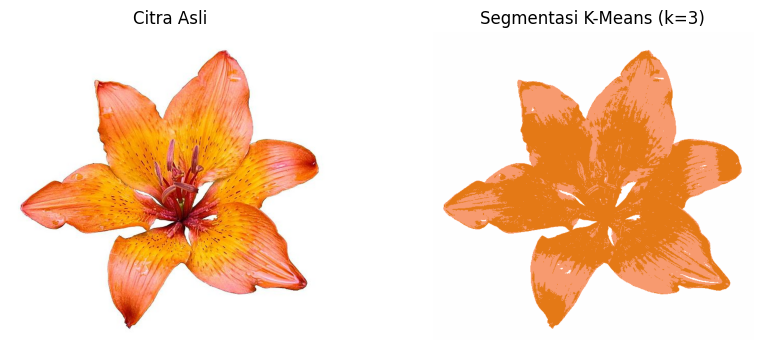

In [ ]:
from sklearn.cluster import KMeans

filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/lily.jpg')
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')
plt.show()

# TUGAS PRAKTIKUM
## Tugas Individu

### 1 & 2

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

### 3

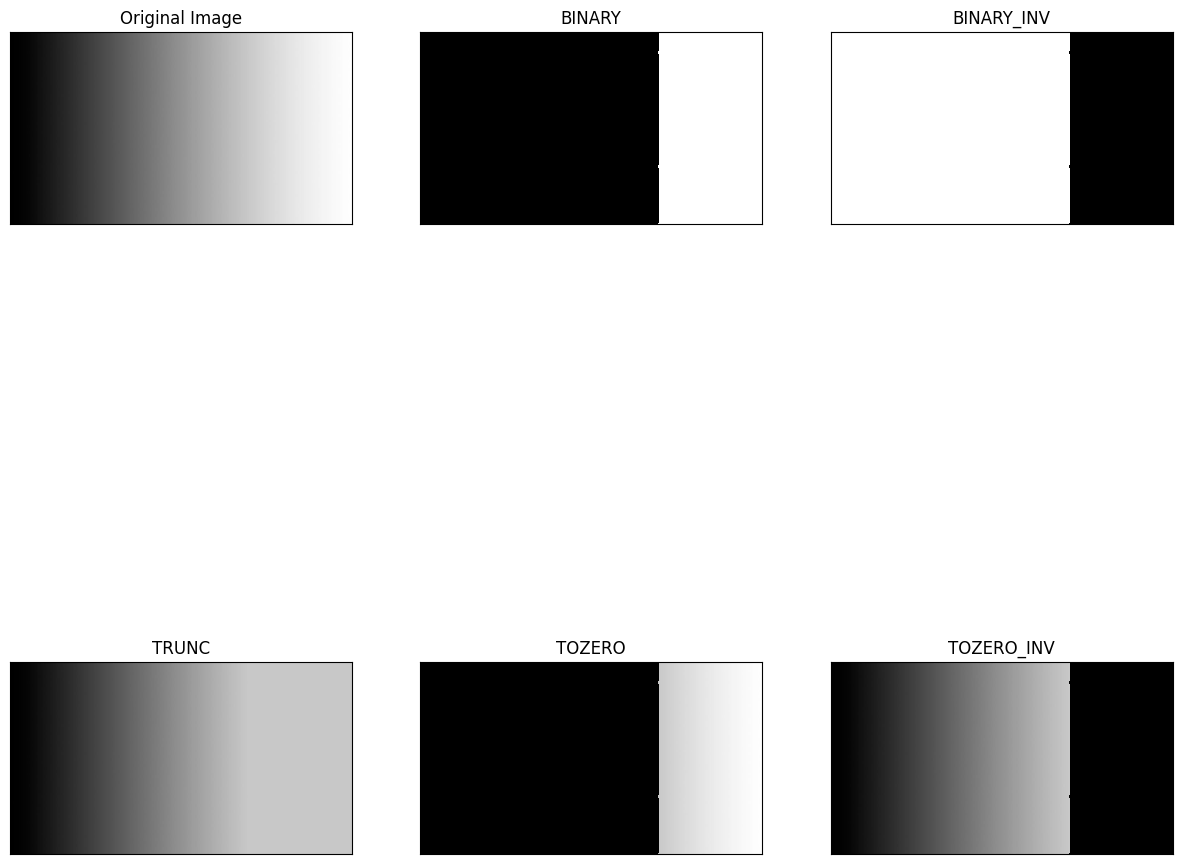

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/gradient.jpg')
img = cv.imread(filename)
thresh = 200
maxValue = 255

ret,thresh1 = cv.threshold(img,thresh,maxValue,cv.THRESH_BINARY)
ret,thresh2 = cv.threshold(img,thresh,maxValue,cv.THRESH_BINARY_INV)
ret,thresh3 = cv.threshold(img,thresh,maxValue,cv.THRESH_TRUNC)
ret,thresh4 = cv.threshold(img,thresh,maxValue,cv.THRESH_TOZERO)
ret,thresh5 = cv.threshold(img,thresh,maxValue,cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img,thresh1,thresh2,thresh3,thresh4,thresh5]

plt.figure(figsize=(15,15))
for i in range(len(images)):
  plt.subplot(2,3,i+1), plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

### 4

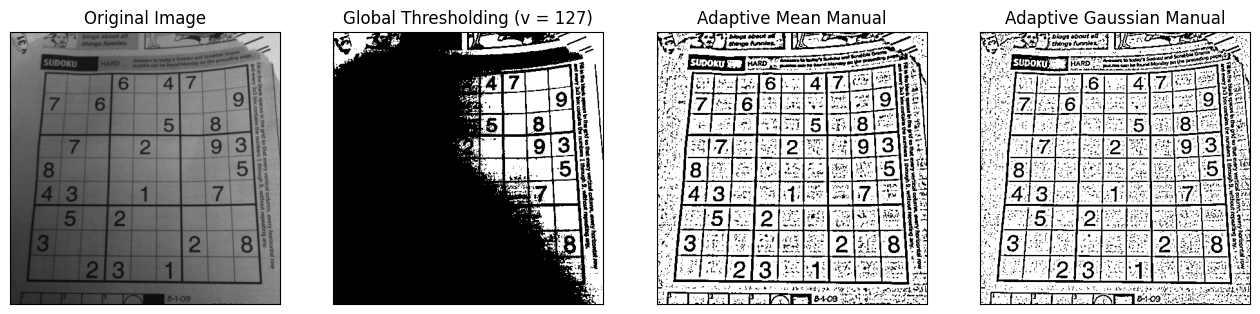

In [ ]:
def adaptive_manual(gray, ukuran=11, C=2, metode='mean', sigma=2):
  r = ukuran // 2
  g = gray.astype(np.float64)
  pad = np.pad(g, r, mode='reflect')
  h, w = gray.shape

  if metode == 'mean':
    bobot = np.ones((ukuran, ukuran))
  else:
    ax = np.arange(ukuran) - r
    k = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    bobot = np.outer(k, k)

  bobot = bobot / bobot.sum()
  rata = np.zeros((h, w))
  for dy in range(ukuran):
    for dx in range(ukuran):
      rata += bobot[dy, dx] * pad[dy:dy+h, dx:dx+w]

  T = rata - C
  return np.where(g > T, 255, 0).astype(np.uint8)

filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/sudoku-original.jpg')
gray = cv.imread(filename, 0)

thresh = 127
th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)
th2 = adaptive_manual(gray, 11, 2, 'mean')
th3 = adaptive_manual(gray, 11, 2, 'gauss', sigma=2)

titles = ['Original Image', 'Global Thresholding (v = 127)', 'Adaptive Mean Manual', 'Adaptive Gaussian Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (16,5))
for i in range(len(citra2)):
  plt.subplot(1,4,i+1),plt.imshow(citra2[i],'gray',vmin=0,vmax=255)
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

### 5
a

114


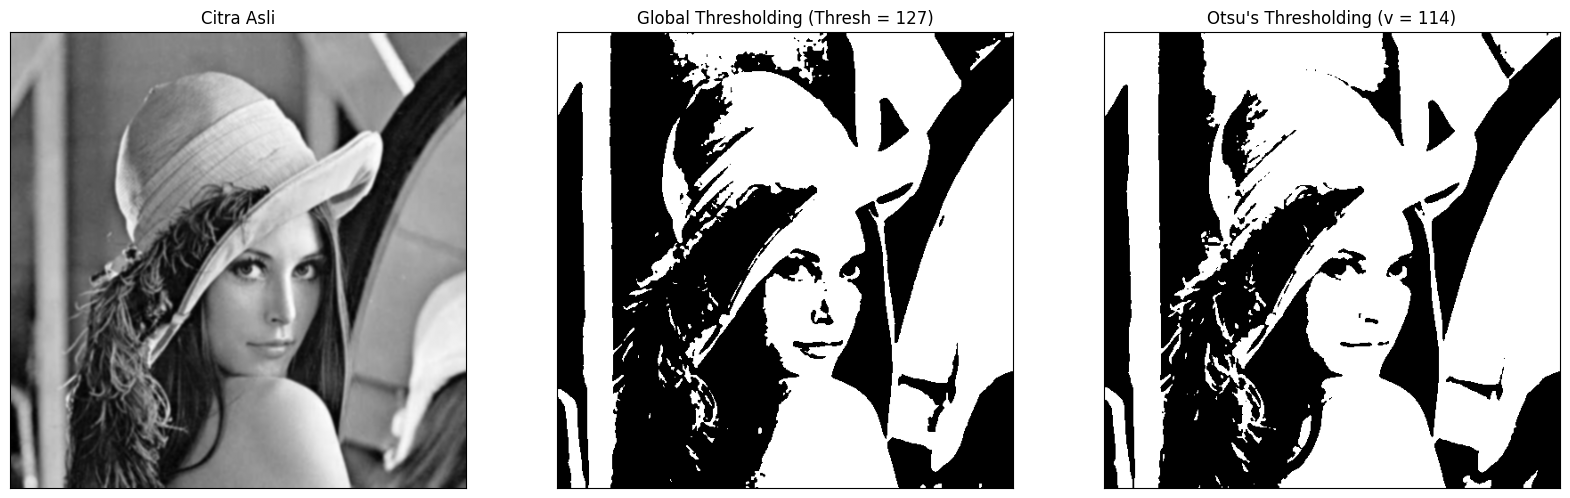

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/lena.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)
  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    if pcb == 0 or pcf == 0:
      continue

    Wb = pcb * mean_weight
    Wf = pcf * mean_weight
    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
    value = Wb * Wf * (mub - muf) ** 2
    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray >= final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
th1 = np.where(blur > thresh, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray',vmin=0,vmax=255)
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

b

152


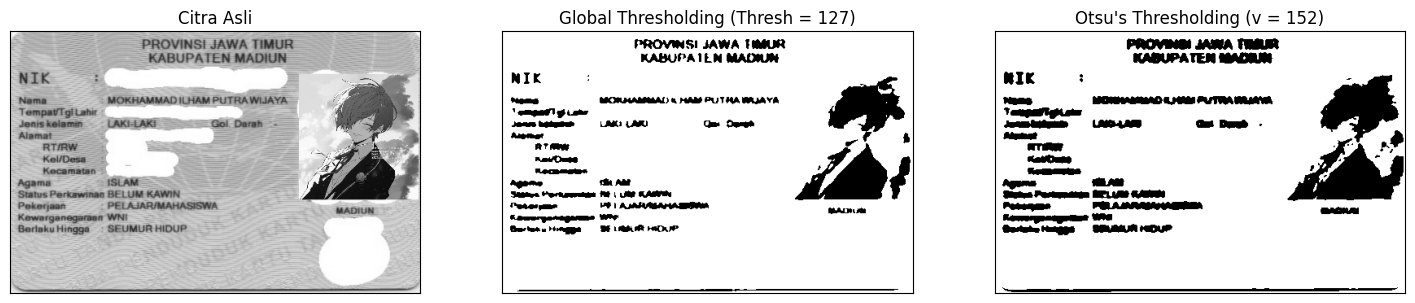

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/244107020139/ktp-lhm.jpeg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
th1 = np.where(blur > thresh, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (Thresh = 127)',
          "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"]
citra3 = [img, th1, otsu_biner]

plt.figure(figsize = (18,5))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray',vmin=0,vmax=255)
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### 6
a

Dalam koin (baris, kolom): (50, 43) | intensitas: 175
Latar (baris, kolom): (90, 230) | intensitas: 68
Tepi koin (baris, kolom): (55, 22) | intensitas: 170


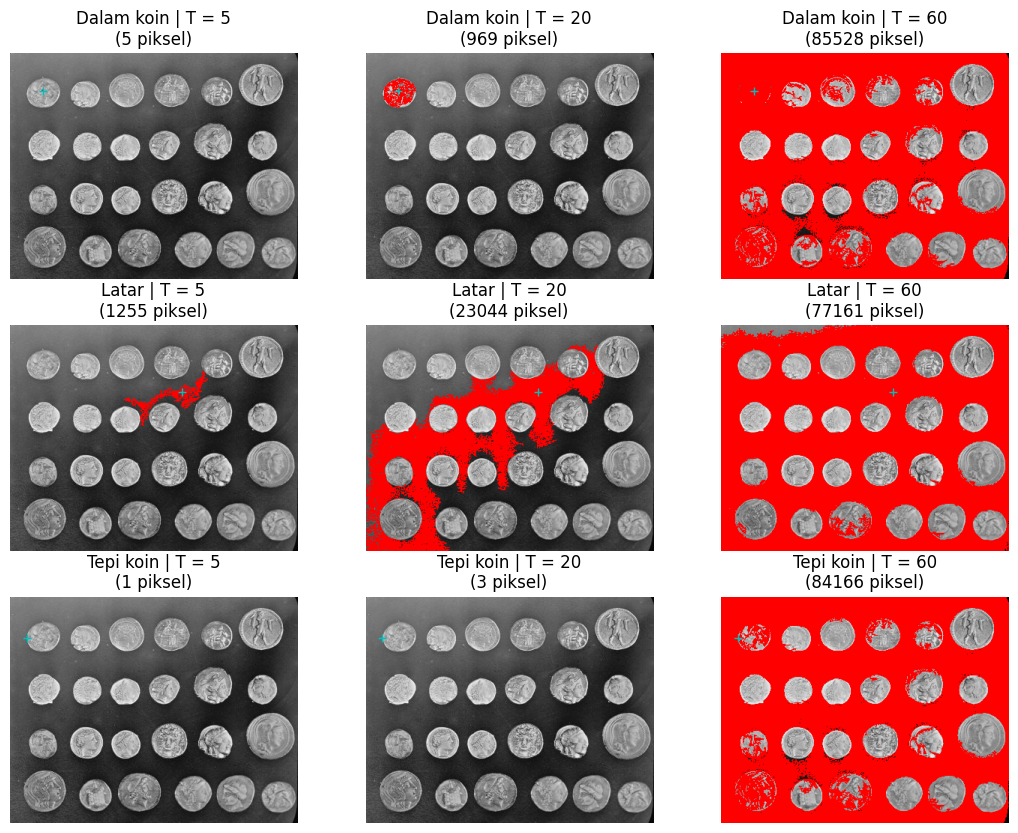

In [ ]:
img = data.coins()
def region_growing(img, seed, T):
  img_f = img.astype(np.float64)
  H, W = img.shape
  mask = np.zeros((H, W), dtype=bool)
  r, c = seed
  mask[r, c] = True
  total, count = img_f[r, c], 1
  antrian = deque([(r, c)])
  while antrian:
    y, x = antrian.popleft()
    for dy, dx in ((-1,0),(1,0),(0,-1),(0,1)):
      ny, nx = y + dy, x + dx
      if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
        if abs(img_f[ny, nx] - total / count) <= T:
          mask[ny, nx] = True
          total += img_f[ny, nx]
          count += 1
          antrian.append((ny, nx))
  return mask

baris = 36
halus = ndi.gaussian_filter(img.astype(float), 1)
k = int(np.argmax(np.abs(np.diff(halus[baris, 43:75]))))
kolom_tepi = 43 + k
seeds = [('Dalam koin', (50, 43)),
        ('Latar', (90, 230)),
        ('Tepi koin', (55, 22))]
for nama, s in seeds:
  print(nama, '(baris, kolom):', s, '| intensitas:', img[s])

Ts = [5, 20, 60]
plt.figure(figsize = (13,10))
n = 1
for nama, seed in seeds:
  for T in Ts:
    mask = region_growing(img, seed, T)
    overlay = np.dstack([img]*3).copy()
    overlay[mask] = [255, 0, 0]
    plt.subplot(3,3,n)
    plt.imshow(overlay)
    plt.plot(seed[1], seed[0], 'c+')
    plt.title(nama + ' | T = ' + str(T) + '\n(' + str(mask.sum()) + ' piksel)')
    plt.axis('off')
    n += 1
plt.show()

b

Jumlah piksel region: 177


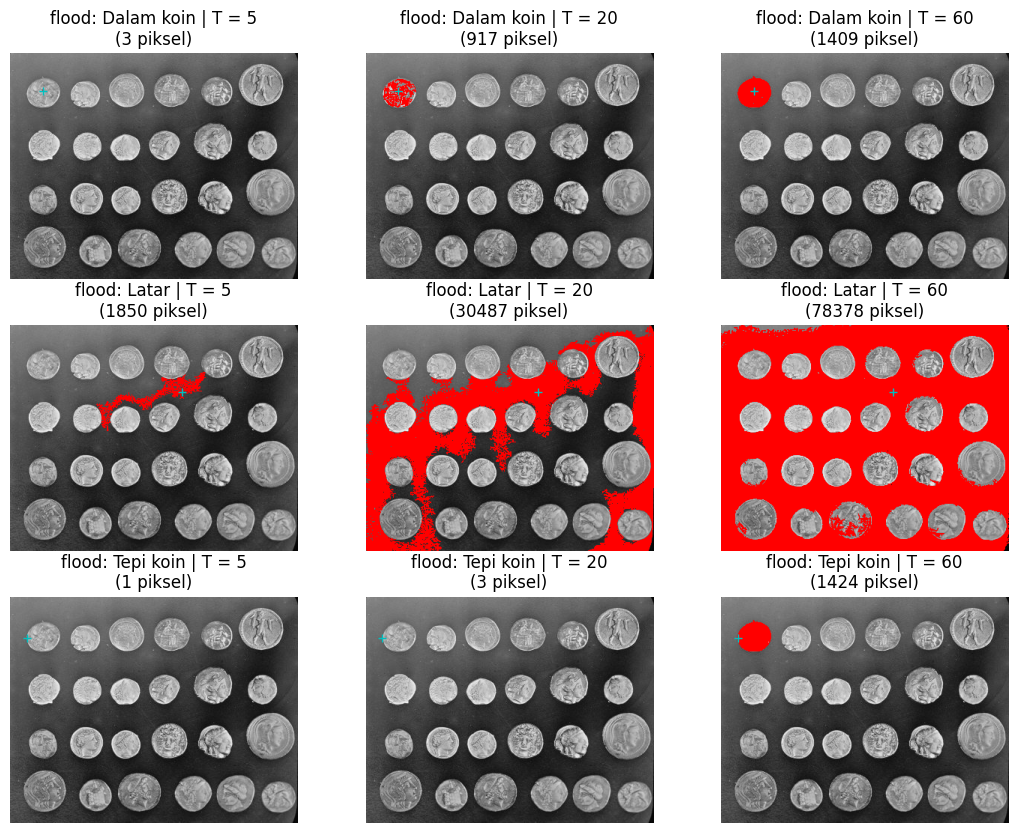

In [ ]:
gray = data.coins()
seed = (121, 63)

region = flood(
  gray,
  seed_point=seed,
  tolerance=20,
  connectivity=1
)
print('Jumlah piksel region:', region.sum())

plt.figure(figsize = (13,10))
n = 1
for nama, s in seeds:
  for T in Ts:
    mask = flood(gray, seed_point=s, tolerance=T, connectivity=1)
    overlay = np.dstack([gray]*3).copy()
    overlay[mask] = [255, 0, 0]
    plt.subplot(3,3,n)
    plt.imshow(overlay)
    plt.plot(s[1], s[0], 'c+')
    plt.title('flood: ' + nama + ' | T = ' + str(T) + '\n(' + str(mask.sum()) + ' piksel)')
    plt.axis('off')
    n += 1
plt.show()

### 7

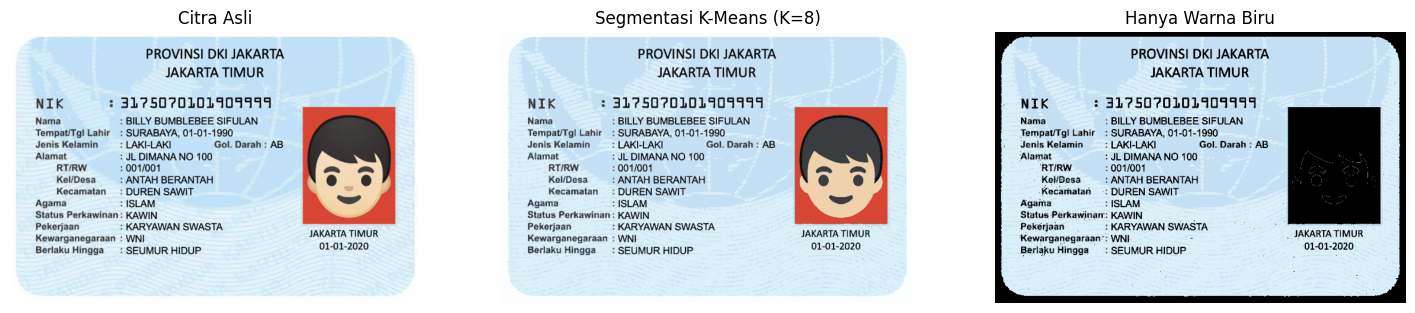

In [ ]:
ktp = cv.cvtColor(cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/ktp_fulan.jpg'), cv.COLOR_BGR2RGB)
Z = ktp.reshape(-1, 3).astype(np.float32)

rng = np.random.default_rng(42)
sampel = Z[rng.choice(len(Z), size=min(50000, len(Z)), replace=False)]
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10).fit(sampel)

labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels].reshape(ktp.shape)

hsv = cv.cvtColor(segmented, cv.COLOR_RGB2HSV)
H, S, V = cv.split(hsv)
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

hanya_biru = np.zeros_like(segmented)
hanya_biru[kelompok_biru] = segmented[kelompok_biru]

titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [ktp, segmented, hanya_biru]
plt.figure(figsize=(18, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i]); plt.title(titles[i]); plt.axis('off')
plt.show()

## Tugas Kelompok

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [ ]:
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output

ktp_list = {
  'KTP 1': '/content/drive/MyDrive/PCVK/Images/244107020139/ktp-lhm.jpeg',
  'KTP 2': '/content/drive/MyDrive/PCVK/Images/244107020139/ktp_najla.jpeg',
  'KTP 3': '/content/drive/MyDrive/PCVK/Images/244107020139/ktp_fatah.jpeg',
}
acuan_list = {
  'KTP 1': ['PROVINSI JAWA TIMUR', 'KABUPATEN MADIUN', 'MOKHAMMAD ILHAM PUTRA WIJAYA', 'LAKI-LAKI',
  'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP', 'MADIUN'],
  'KTP 2': ['PROVINSI JAWA TIMUR', 'KABUPATEN MALANG', 'NAJLA NURICIA LAUDY', 'PEREMPUAN',
  'ISLAM', 'BELUM KAWIN', 'BELUM/TIDAK BEKERJA', 'WNI', 'SEUMUR HIDUP', 'MALANG'],
  'KTP 3': ['PROVINSI JAWA TIMUR', 'KABUPATEN MALANG', 'MUHAMMAD FATAHILLAH ATHABRANI', 'LAKI-LAKI',
  'ISLAM', 'BELUM KAWIN', 'PELAJAR/MAHASISWA', 'WNI', 'SEUMUR HIDUP', 'MALANG'],
}
bahasa = 'ind'
psm = '--psm 6'
batas = 60
nama = ['Berwarna', 'Otsu', 'Adaptive']

<Figure size 1800x500 with 0 Axes>

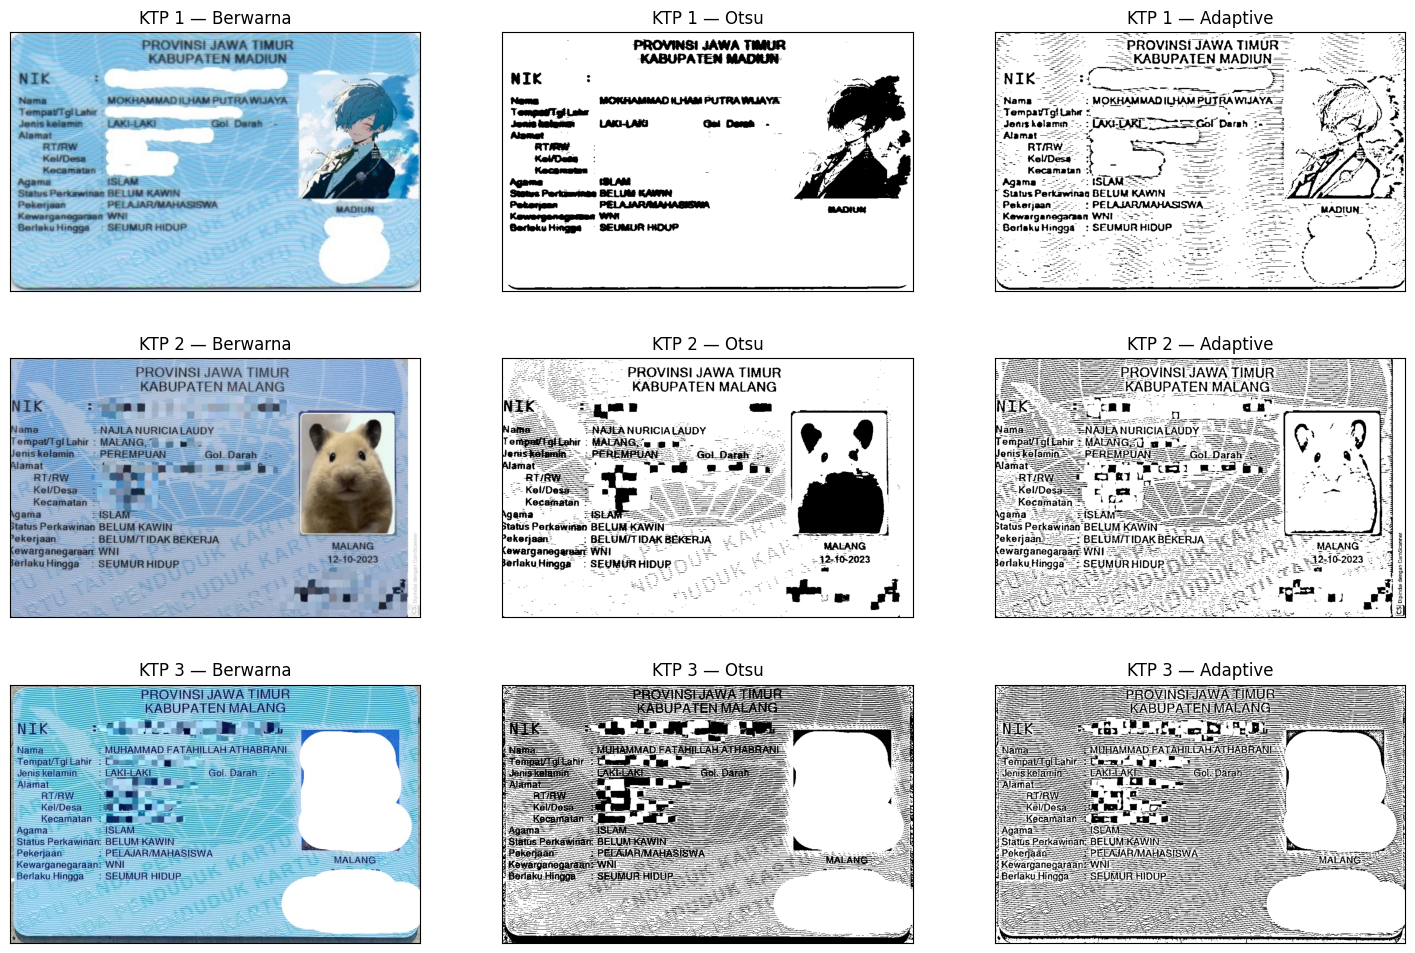

In [ ]:
plt.figure(figsize=(18,5))
n = 1

plt.figure(figsize=(18,12))
n = 1

for k in ktp_list:
  img = cv.imread(ktp_list[k])
  img = cv.resize(img, (1000, 630))
  berwarna = cv.cvtColor(img, cv.COLOR_BGR2RGB)
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  ret, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
  adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 15)
  citra = [berwarna, otsu, adaptive]

  for i in range(3):
    plt.subplot(3,3,n),plt.imshow(citra[i],'gray')
    plt.title(k + ' — ' + nama[i])
    plt.xticks([]),plt.yticks([])
    n += 1
plt.show()


<Figure size 1800x1200 with 0 Axes>

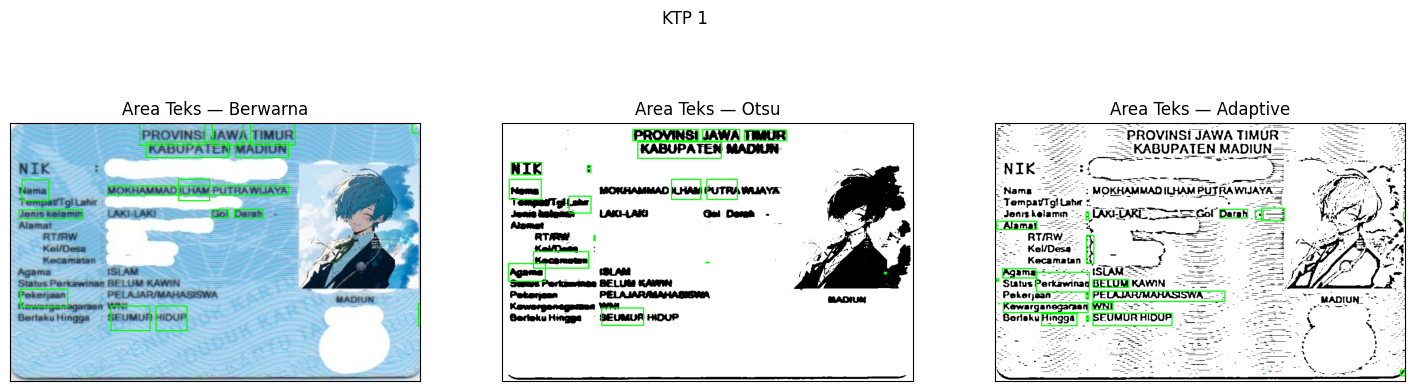

========== KTP 1 — BERWARNA ==========
23 - PROVINSI JAWA TIMUR 2
KABUPATEN MADIUN
“— Gang Oo”
— Nama MOKHAMMAD ILHAM PUTRAWIJAYA—— SEN.
TampatTgitahit Kes
| Jeniskelamin LAKI-LAKI Gol Darah -- "yu
LM Hp” 74 2
KolDesa F .
. Pekerjaan -. MADIUN 2.
. Berteku Hingga SEUMUR HIDUP : 3 |
CE — AE AI

Rata-rata confidence: 44.24

========== KTP 1 — OTSU ==========
| PROVINSI JAWA TIMUR
: “KABUPATEN MADIIN:-
NIK : Nae
Nama MOKHAMMAD ILHAM PUTRA WLAYA » |
Tempat Tai Lahu " G1
RT : nh PA Ha
Kadas: 2
Kecamatan - PEP”,
Agama #SLAKL : PP .
Kaoworganagaraan
Berieku Hingga SEUMUR MDUP
aa” —”“”“”

Rata-rata confidence: 48.3

========== KTP 1 — ADAPTIVE ==========
Bo SEA TPROVINSIJAWA TIMUR 5 1
Ia— TEE 5EKABUPATEN MADIUN —.— ———- ja
z aa aa Mana
NIK 5533 AA LS:
. Te ML A.M E— 4 23 Ta M3
1 Nama ——: MOKHAMMADILHAMPUTRAWWAYA CA KI
-TempavTgilae » ON 25 Aan DE
“Jan kelamin -. : LAKITAKE TO Gol Darah 17 — 21) £ :
“Alamat 4 IN aa — | ii
T5 RTRW. 1 Te ai Aan
FA KolDesa 4 YP ANA
5. Kecamatan. Of —2—. -——. ap, T

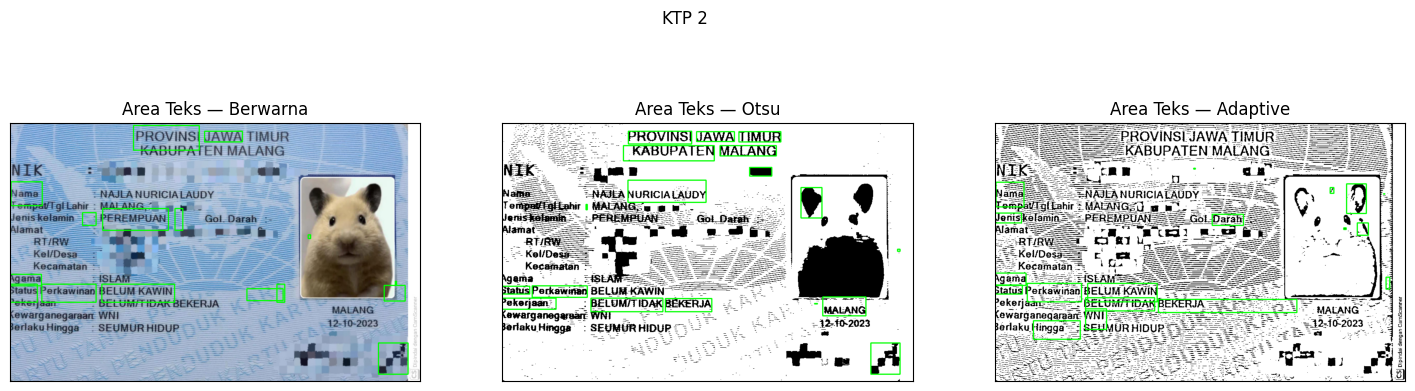

========== KTP 2 — BERWARNA ==========
———- —  —  —————3———————— TT
P5 PROVINSI JAWA TIMUR”
00 KKBUPATENMALANG
No “daa TT
alamat

Nama ——— “NAJIANURICIALAUDY ———— -
Jeniskelamin —- PEREMPUAN — — Gol Darah — An
Alamat j9 pa ama | :
PB 114 .
5 KolDen ia PA L
ma MI

Agama ——— SPAM” |
Status Perkawinan BELUMKAWIN —————— — - 4 mi 3
ea ea Ea —
sa 5 “en
an AE Aa 5 :
— 2 AA —— TI — — Ya Sa A

Rata-rata confidence: 28.71

========== KTP 2 — OTSU ==========
Ga Ga PROVINSI JAWA TIMUR

2. “TEBEL KABUPATEN MALANG
La ka -
Nama NASA NURICIALAUDY bana
Tempatigtkahir : MALANG: gm. TT ban ? )
Alamat “2... wa acms.

Pe — ss — El - .
| Kecamatan: PA
Ngama —- HSEAME2 5
Statis Perkawinan BELUM-KAWIN ””—-—— ——...' — MNNNNNNN |
Pekerjaan: — : BELUM/TIDAK BEKERJA EP On 5 MALANG
tewarganegarsan WNI. C—” |. 3 2 #naoo3
rlaku Hingga : SEUMURHIDUP "3

| . | | - ST SAR ai ai “ aka rn A

Rata-rata confidence: 32.92

========== KTP 2 — ADAPTIVE ==========
3 PROVINSIJAWATIMUR
Ae
NIK 2 taN : ah —

Ba rab oo ..—o il — —.

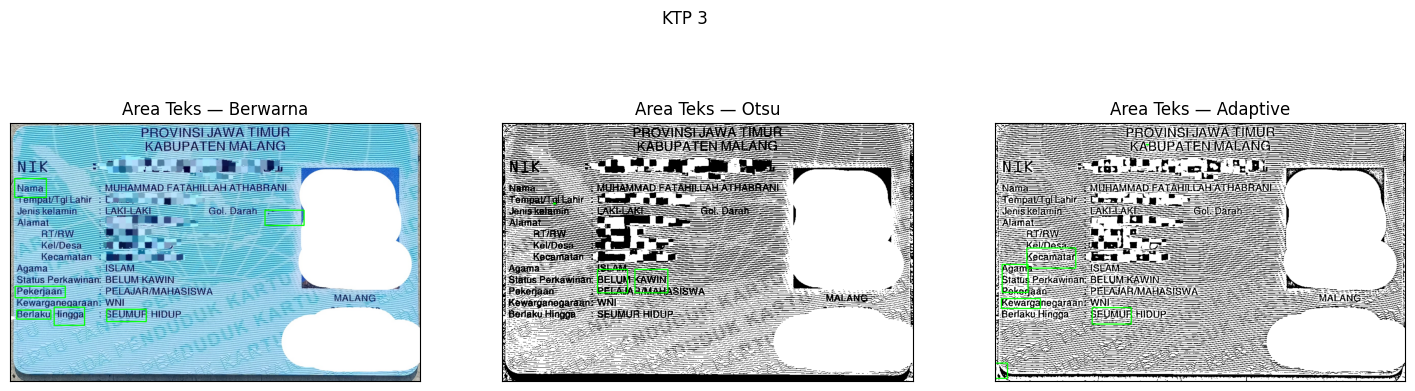

========== KTP 3 — BERWARNA ==========
PA ABU PA EN EANG PPL
SE  KABUPATENYAPANG ——” “&
PP - Mo —y “S—
Name MUHAMMAD FATAHIEEAH-AT HABRANI Y—
Pena Ea tah Daan 2 23
Aa ————3 PP —-— 2
Aap La ———— —
Agama SASEAM -
Pekerjaan ——— : PEKAJARIMAHASISWA ang
Berlaku Hingga —: SEUMUR HIDUP EP —— —

Rata-rata confidence: 23.55

========== KTP 3 — OTSU ==========
AP Pa AA ANA EA
2 AN Pe EA 3
AA AE
0 pevpotenyAkang
PA
aa ani 2 HAN P5
Heal 2 5. (“SER
AA 5 Sa - Te R5
idea PAKA Sa Darah - | P3
“ama Ada —
Ke EN ———— ET
T Agama 5 span E.
4 Aga ——&&T5—-: -
Status Perkawinan BELUM KAWIN 5 Ih PE
CPekeraa —— PERAA MABASSWA Na
MA Air AP — MALANG S5
I Kewarganonaran WN ap PAP
mee ————B -—
EA EA RL — no...

Rata-rata confidence: 18.11

========== KTP 3 — ADAPTIVE ==========
NA Jaa ee EA LA Te ESA —5t-t-5-—58---— s8.
E——— 2 PROVINSHAWASMD PA Aa
PS KOVINSISAWA TIMUR”
E 5 NA Ta AP ws
3  KABUPATENNALANG EP
KE Pi Pa Pe —
Maa AN io II ——
(ama  NNBAMMAD FATAHIAH M HABHANG :: 3
bana it MALE FAR AE DAOBANIE: Eh
Pe en Ma

In [ ]:
hasil = {}
for k in ktp_list:
  img = cv.imread(ktp_list[k])
  if img is None:
    raise FileNotFoundError('File tidak terbaca: ' + ktp_list[k])
  img = cv.resize(img, (1000, 630))
  berwarna = cv.cvtColor(img, cv.COLOR_BGR2RGB)
  gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
  ret, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
  adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 15)
  citra = [berwarna, otsu, adaptive]

  teks, conf_rata, kotak_list = [], [], []
  for i in range(3):
    gambar = citra[i]
    teks.append(pytesseract.image_to_string(gambar, lang=bahasa, config=psm))
    data = pytesseract.image_to_data(gambar, lang=bahasa, config=psm, output_type=Output.DICT)
    kotak = gambar.copy()
    if kotak.ndim == 2:
      kotak = cv.cvtColor(kotak, cv.COLOR_GRAY2RGB)
    semua_conf = []
    for j in range(len(data['text'])):
      conf = float(data['conf'][j])
      if data['text'][j].strip() != '' and conf >= 0:
        semua_conf.append(conf)
      if conf > batas:
        x, y = data['left'][j], data['top'][j]
        w, h = data['width'][j], data['height'][j]
        cv.rectangle(kotak, (x, y), (x+w, y+h), (0,255,0), 2)
    conf_rata.append(np.mean(semua_conf) if len(semua_conf) > 0 else 0)
    kotak_list.append(kotak)

  hasil[k] = {'teks': teks, 'conf': conf_rata, 'kotak': kotak_list}

plt.figure(figsize=(18,12))
n = 1
for k in ktp_list:
  plt.figure(figsize=(18,5))
  for i in range(3):
    plt.subplot(1,3,i+1),plt.imshow(hasil[k]['kotak'][i])
    plt.title('Area Teks — ' + nama[i])
    plt.xticks([]),plt.yticks([])
  plt.suptitle(k)
  plt.show()

  for i in range(3):
    print('========== ' + k + ' — ' + nama[i].upper() + ' ==========')
    print(hasil[k]['teks'][i])
    print('Rata-rata confidence:', round(hasil[k]['conf'][i], 2))
    print()

In [ ]:
def terbaca(item, hasil_ocr):
  return item.strip().lower() in hasil_ocr.strip().lower()

semua_ringkasan = []

for k in ktp_list:
  acuan = acuan_list[k]

  tabel = []
  for no in range(10):
    baris = {'No.': no+1, 'Teks sebenarnya': acuan[no]}
    for i in range(3):
      baris['OCR ' + nama[i]] = acuan[no] if terbaca(acuan[no], hasil[k]['teks'][i]) else '(salah / tidak terbaca)'
    tabel.append(baris)
  print('===== TABEL PERBANDINGAN —', k, '=====')
  print(pd.DataFrame(tabel).to_string(index=False))

  for i in range(3):
    tepat = sum(terbaca(item, hasil[k]['teks'][i]) for item in acuan)
    semua_ringkasan.append({'KTP': k,
                            'Citra masukan OCR': nama[i],
                            'Item terbaca tepat': tepat,
                            'Kecocokan (%)': tepat / 10 * 100,
                            'Rata-rata confidence': round(hasil[k]['conf'][i], 2)})
  print()

ringkasan = pd.DataFrame(semua_ringkasan)

print('===== RINGKASAN PER KTP =====')
print(ringkasan.to_string(index=False))

print('\n===== RATA-RATA DARI 3 KTP =====')
rata = ringkasan.groupby('Citra masukan OCR')[['Item terbaca tepat', 'Kecocokan (%)', 'Rata-rata confidence']].mean().round(2)
rata = rata.loc[nama]
print(rata)

terbaik = rata['Kecocokan (%)'].idxmax()
conf_max = rata['Rata-rata confidence'].idxmax()
print('\nPembacaan paling tepat (rata-rata):', terbaik)
print('Confidence tertinggi (rata-rata)  :', conf_max, '| sama dengan yang terbaik?', terbaik == conf_max)

===== TABEL PERBANDINGAN — KTP 1 =====
 No.              Teks sebenarnya            OCR Berwarna                OCR Otsu            OCR Adaptive
   1          PROVINSI JAWA TIMUR     PROVINSI JAWA TIMUR     PROVINSI JAWA TIMUR (salah / tidak terbaca)
   2             KABUPATEN MADIUN        KABUPATEN MADIUN (salah / tidak terbaca)        KABUPATEN MADIUN
   3 MOKHAMMAD ILHAM PUTRA WIJAYA (salah / tidak terbaca) (salah / tidak terbaca) (salah / tidak terbaca)
   4                    LAKI-LAKI               LAKI-LAKI (salah / tidak terbaca) (salah / tidak terbaca)
   5                        ISLAM (salah / tidak terbaca) (salah / tidak terbaca)                   ISLAM
   6                  BELUM KAWIN (salah / tidak terbaca) (salah / tidak terbaca)             BELUM KAWIN
   7            PELAJAR/MAHASISWA (salah / tidak terbaca) (salah / tidak terbaca)       PELAJAR/MAHASISWA
   8                          WNI (salah / tidak terbaca) (salah / tidak terbaca)                     WNI
   9   